# Public data experiments
This is the notebook to run the public data experiment

In [1]:
import sys
from pathlib import Path

# Add the workspace root to sys.path
workspace_root = Path("/Users/eduardohome/workspace/benchmark_credit_scoring")
if str(workspace_root) not in sys.path:
    sys.path.insert(0, str(workspace_root))

# Now you can import from src
from src.utils.csv_config import read_csv_by_name, create_imbalanced_datasets, merge_xai_results
from src.model.functions import save_model, load_model, get_split_data
from src.xai.functions import get_train_iterations_shap, compute_xai_metrics_from_shap
from src.graph.functions import plot_model_boxplot

try:
    from src.model.functions import get_train_model
except Exception as exc:
    # provide helpful message if import fails
    print("Failed to import model utilities:", exc)
    print("This often means a missing dependency such as libomp for LightGBM.")
    print("On macOS you can install it with `brew install libomp` and then restart the kernel.")
    raise

# General imports
import pandas as pd
from pathlib import Path

In [2]:
# -------------------------
# Settings
# -------------------------
data_dir = Path("/Users/eduardohome/workspace/benchmark_credit_scoring/data")
datasets_to_run = ["australian", "german", "japan", "kgccdea", "taiwan", "th02"] #kggmsc
datasets_to_run = ["german"]
target_col = "target"

# Edit this list whenever you want more/less imbalance datasets
imbalance_levels = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
imbalance_levels = [5, 10, 15]
n_iterations = 10
percentage = 90

# list of estimators understood by functions.get_model
model_choices = ["RandomForest", "XGBoost", "LightGBM", "BoostDT", "BoostSGB", "BagNN", "AdaBoost-DT", "ANN"] #, "SVM-Rbf"
model_choices = ["XGBoost", "RandomForest"] #, "SVM-Rbf"
product = "default"


## Create the imbalance datasets

In [3]:
for dataset_name in datasets_to_run:
    dataset_path = data_dir / "input" / f"{dataset_name}.csv"
    # Check if file exists and read it using the helper from src.csv_config
    if dataset_path.exists():
        # Use the dataset-specific defaults (german uses tab separator)
        create_imbalanced_datasets(
            dataset_name=dataset_name,
            data_dir=data_dir,
            imbalance_levels=imbalance_levels,  # <-- modify freely
            target_col="target",
            )

Original dataset: german
Total samples: 1000
Positive samples: 300
Negative samples: 700
Positive rate: 0.3000

german_5.csv | Total=736 | Pos=36 | Rate=0.0489 | keep all negatives (700), downsample positives to 36
german_10.csv | Total=777 | Pos=77 | Rate=0.0991 | keep all negatives (700), downsample positives to 77
german_15.csv | Total=823 | Pos=123 | Rate=0.1495 | keep all negatives (700), downsample positives to 123

Finished generating imbalanced datasets.


## Train the models

In [4]:
results = []

for dataset_name in datasets_to_run:
    # variants for this dataset
    dataset_variants = [dataset_name] + [f"{dataset_name}_{pct}" for pct in imbalance_levels]

    # ensure output dir exists
    out_dir = data_dir / "output" / dataset_name
    out_dir.mkdir(parents=True, exist_ok=True)

    print("\n" + "#" * 90)
    print(f"BASE DATASET: {dataset_name}")
    print("#" * 90)

    for dataset_variant in dataset_variants:
        dataset_path = data_dir / "intermediate" / dataset_name / f"{dataset_variant}.csv"

        if not dataset_path.exists():
            print(f"[SKIP] File not found: {dataset_path}")
            continue

        # Read each dataset variant (uses your resolver logic in csv_config.py)
        df = pd.read_csv(str(dataset_path))

        # Basic safety checks
        if target_col not in df.columns:
            print(f"[SKIP] {dataset_variant}: target column '{target_col}' not found. Columns={list(df.columns)[:10]}...")
            continue

        # Quick dataset stats
        n_total = len(df)
        # Make sure sum/mean work even if target is int-like
        y = pd.to_numeric(df[target_col], errors="coerce")
        n_pos = int((y == 1).sum())
        pos_rate = float((y == 1).mean())

        print("\n" + "=" * 80)
        print(f"DATASET: {dataset_variant} | n={n_total} | pos={n_pos} | pos_rate={pos_rate:.4f}")
        print("=" * 80)

        # Prepare column lists for this df
        feature_cols     = df.columns.tolist()
        numerical_cols   = df.select_dtypes(include="number").columns.tolist()
        categorical_cols = df.select_dtypes(include="object").columns.tolist()
        ids_cols         = []
        target_cols      = [target_col]
        exclude_cols     = []

        # Optionally skip if only one class present (prevents stratify crash)
        n_neg = n_total - n_pos
        if n_pos == 0 or n_neg == 0:
            print(f"[SKIP] {dataset_variant}: only one class present (pos={n_pos}, neg={n_neg}).")
            continue

        for model_choice in model_choices:
            print(f"\n=== training {model_choice} on {dataset_variant} ===")

            pipeline, best_params, best_score = get_train_model(
                data=df,
                feature_cols=feature_cols,
                numerical_cols=numerical_cols,
                categorical_cols=categorical_cols,
                ids_cols=ids_cols,
                target_cols=target_cols,
                exclude_cols=exclude_cols,
                product=product,
                algorithm=model_choice,
                test_mode=True,  # set False for full search
            )

            print("Best hyperparameters:", best_params)
            print("Best CV score:", best_score)

            model_path = out_dir / "model" /f"{dataset_variant}_{model_choice}.pkl"
            save_model(str(model_path), pipeline, environment="local")
            print(f"trained pipeline saved to {model_path}")

            results.append(
                {
                    "base_dataset": dataset_name,
                    "dataset_variant": dataset_variant,
                    "model": model_choice,
                    "n_total": n_total,
                    "n_pos": n_pos,
                    "pos_rate": pos_rate,
                    "params": best_params,
                    "score": best_score,
                }
            )

results_df = pd.DataFrame(results)
results_df


##########################################################################################
BASE DATASET: german
##########################################################################################
[SKIP] File not found: /Users/eduardohome/workspace/benchmark_credit_scoring/data/intermediate/german/german.csv

DATASET: german_5 | n=736 | pos=36 | pos_rate=0.0489

=== training XGBoost on german_5 ===
Search space for algorithm=XGBoost, product=default, test_mode=True: {'model__n_estimators': Integer(low=50, high=200, prior='uniform', transform='identity'), 'model__max_depth': Integer(low=3, high=8, prior='uniform', transform='identity'), 'model__learning_rate': Real(low=0.01, high=0.1, prior='log-uniform', transform='identity'), 'model__scale_pos_weight': Integer(low=1, high=10, prior='uniform', transform='identity'), 'model__gamma': Real(low=1.0, high=5.0, prior='uniform', transform='identity'), 'model__subsample': Real(low=0.5, high=1.0, prior='uniform', transform='identity'), '

,base_dataset,dataset_variant,model,n_total,n_pos,pos_rate,params,score
0,german,german_5,XGBoost,736,36,0.048913,"{'model__booster': 'gbtree', 'model__colsample...",0.048540
1,german,german_5,RandomForest,736,36,0.048913,"{'model__bootstrap': False, 'model__class_weig...",0.163498
2,german,german_10,XGBoost,777,77,0.099099,"{'model__booster': 'gbtree', 'model__colsample...",0.192605
3,german,german_10,RandomForest,777,77,0.099099,"{'model__bootstrap': False, 'model__class_weig...",0.211322
4,german,german_15,XGBoost,823,123,0.149453,"{'model__booster': 'gbtree', 'model__colsample...",0.314742
5,german,german_15,RandomForest,823,123,0.149453,"{'model__bootstrap': False, 'model__class_weig...",0.427775


## SHAP iterations

In [5]:
# -------------------------
# Loop XAI iterations
# -------------------------
for dataset_name in datasets_to_run:

    dataset_variants = [dataset_name] + [f"{dataset_name}_{lvl}" for lvl in imbalance_levels]

    out_dir = data_dir / "output" / dataset_name
    out_dir.mkdir(parents=True, exist_ok=True)

    print("\n" + "#" * 90)
    print(f"BASE DATASET: {dataset_name}")
    print("#" * 90)

    for dataset_variant in dataset_variants:

        dataset_path = data_dir / "intermediate" / dataset_name / f"{dataset_variant}.csv"

        if not dataset_path.exists():
            print(f"[SKIP] File not found: {dataset_path}")
            continue

        # Same reader used during training
        path = str(dataset_path)
        df = pd.read_csv(str(path))

        if target_col not in df.columns:
            print(f"[SKIP] {dataset_variant}: target column '{target_col}' not found.")
            continue

        n_total = len(df)
        y = pd.to_numeric(df[target_col], errors="coerce")
        n_pos = int((y == 1).sum())
        pos_rate = float((y == 1).mean())

        print("\n" + "=" * 80)
        print(f"DATASET: {dataset_variant} | n={n_total} | pos={n_pos} | pos_rate={pos_rate:.4f}")
        print("=" * 80)

        n_neg = n_total - n_pos
        if n_pos == 0 or n_neg == 0:
            print(f"[SKIP] {dataset_variant}: only one class present.")
            continue

        # Same column preparation as training
        feature_cols     = df.columns.tolist()
        numerical_cols   = df.select_dtypes(include="number").columns.tolist()
        categorical_cols = df.select_dtypes(include="object").columns.tolist()
        ids_cols         = []
        target_cols      = [target_col]
        exclude_cols     = []

        # Data split
        x_train, x_test, y_train, y_test, numerical, categorical = get_split_data(
            data=df,
            feature_cols=feature_cols,
            numerical_cols=numerical_cols,
            categorical_cols=categorical_cols,
            ids_cols=ids_cols,
            target_cols=target_cols,
            exclude_cols=exclude_cols,
            random_state=123,
        )

        for model_choice in model_choices:

            model_path = out_dir / "model" /f"{dataset_variant}_{model_choice}.pkl"

            if not model_path.exists():
                print(f"[SKIP] Model not found: {model_path}")
                continue

            print(f"Running XAI iterations for {dataset_variant} | {model_choice}")

            pipeline = load_model(str(model_path))

            df_shap = get_train_iterations_shap(
                pipeline=pipeline,
                x_train=x_train,
                x_test=x_test,
                y_train=y_train,
                n_iterations=n_iterations,
                percentage=percentage,
            )
            # ----------------------------
            # Create output folder
            # ----------------------------
            result_dir = out_dir / "xai" / f"{model_choice}" / f"{dataset_variant}" / "shap_values"
            result_dir.mkdir(parents=True, exist_ok=True)

            # ----------------------------
            # Save outputs
            # ----------------------------
            df_shap.to_csv(
                result_dir / f"{dataset_variant}_{model_choice}_shap_values.csv",
                index=False
            )

            print(f"[OK] Saved results to {result_dir}")


##########################################################################################
BASE DATASET: german
##########################################################################################
[SKIP] File not found: /Users/eduardohome/workspace/benchmark_credit_scoring/data/intermediate/german/german.csv

DATASET: german_5 | n=736 | pos=36 | pos_rate=0.0489
Running XAI iterations for german_5 | XGBoost
Model loaded successfully from local path /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/german/model/german_5_XGBoost.pkl
[OK] Saved results to /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/german/xai/XGBoost/german_5/shap_values
Running XAI iterations for german_5 | RandomForest
Model loaded successfully from local path /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/german/model/german_5_RandomForest.pkl
[OK] Saved results to /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/german/xai/RandomForest/ger

## Interpretability metrics

In [6]:
# -------------------------
# Loop XAI metrics from saved SHAP
# -------------------------
for dataset_name in datasets_to_run:

    dataset_variants = [dataset_name] + [f"{dataset_name}_{lvl}" for lvl in imbalance_levels]

    out_dir = data_dir / "output" / dataset_name
    out_dir.mkdir(parents=True, exist_ok=True)

    print("\n" + "#" * 90)
    print(f"BASE DATASET: {dataset_name}")
    print("#" * 90)

    for dataset_variant in dataset_variants:

        for model_choice in model_choices:

            print(f"Computing XAI metrics for {dataset_variant} | {model_choice}")

            # --------------------------------------------------
            # Load previously saved SHAP file
            # --------------------------------------------------
            shap_dir = out_dir / "xai" / f"{model_choice}" / f"{dataset_variant}" / "shap_values"
            shap_path = shap_dir / f"{dataset_variant}_{model_choice}_shap_values.csv"

            if not shap_path.exists():
                print(f"[SKIP] SHAP file not found: {shap_path}")
                continue

            df_shap = pd.read_csv(shap_path)

            # Optional sanity check
            required_cols = {"n_iteration", "index"}
            missing_cols = required_cols - set(df_shap.columns)
            if missing_cols:
                print(f"[SKIP] Missing required columns in SHAP file: {missing_cols}")
                continue

            # --------------------------------------------------
            # Compute metrics from saved SHAP
            # --------------------------------------------------
            (
                df_ranking_local,
                extra_local,
                df_ranking_global,
                df_resume_local,
                df_resume_global,
                df_resume,
            ) = compute_xai_metrics_from_shap(df_shap)

            # --------------------------------------------------
            # Create output folders
            # --------------------------------------------------
            metrics_dir = out_dir / "xai" / f"{model_choice}" / f"{dataset_variant}" / "metrics"
            metrics_dir.mkdir(parents=True, exist_ok=True)

            # --------------------------------------------------
            # Save outputs
            # --------------------------------------------------
            df_ranking_local.to_csv(
                metrics_dir / f"{dataset_variant}_{model_choice}_ranking_local.csv",
                index=False
            )

            extra_local.to_csv(
                metrics_dir / f"{dataset_variant}_{model_choice}_ranking_extra_local.csv",
                index=False
            )

            df_ranking_global.to_csv(
                metrics_dir / f"{dataset_variant}_{model_choice}_ranking_global.csv",
                index=False
            )

            df_resume_local.to_csv(
                metrics_dir / f"{dataset_variant}_{model_choice}_resume_local.csv",
                index=False
            )

            df_resume_global.to_csv(
                metrics_dir / f"{dataset_variant}_{model_choice}_resume_global.csv",
                index=False
            )

            df_resume.to_csv(
                metrics_dir / f"{dataset_variant}_{model_choice}_summary.csv",
                index=False
            )

            print(f"[OK] Saved metrics to {metrics_dir}")


##########################################################################################
BASE DATASET: german
##########################################################################################
Computing XAI metrics for german | XGBoost
[SKIP] SHAP file not found: /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/german/xai/XGBoost/german/shap_values/german_XGBoost_shap_values.csv
Computing XAI metrics for german | RandomForest
[SKIP] SHAP file not found: /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/german/xai/RandomForest/german/shap_values/german_RandomForest_shap_values.csv
Computing XAI metrics for german_5 | XGBoost
[OK] Saved metrics to /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/german/xai/XGBoost/german_5/metrics
Computing XAI metrics for german_5 | RandomForest
[OK] Saved metrics to /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/german/xai/RandomForest/german_5/metrics
Computing XAI metrics

## Summary results

In [7]:
merge_xai_results(
    data_dir=data_dir,
    datasets_to_run=datasets_to_run,
    imbalance_levels=imbalance_levels,
    model_choices=model_choices,
)


Processing dataset: german
Saved raw merged dataset: /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/german/xai/german_xai_all_models.csv
Saved normalized merged dataset: /Users/eduardohome/workspace/benchmark_credit_scoring/data/output/german/xai/german_xai_all_models_normalized.csv


## Read data 

In [8]:
import pandas as pd
from pathlib import Path


def load_xai_file(
    data_dir,
    dataset_name,
    dataset_variant=None,
    model_choice=None,
    file_type="summary",
    normalized=False,
):
    """
    Load saved XAI result files.

    Parameters
    ----------
    data_dir : str | Path
        Base project directory.
    dataset_name : str
        Dataset name (e.g. "german").
    dataset_variant : str | None
        Variant name (e.g. "german_5").
        Required for standard file types.
    model_choice : str | None
        Model name (e.g. "XGBoost").
        Required for standard file types.
    file_type : str
        Which file to load.

        Standard examples:
            "summary"
            "resume_local"
            "resume_global"

        Special values:
            "all_models"

    normalized : bool, default=False
        Only used when file_type="all_models".

        False -> load raw file:
            {dataset_name}_xai_all_models.csv

        True -> load normalized file:
            {dataset_name}_xai_all_models_normalized.csv

    Returns
    -------
    pd.DataFrame
    """

    data_dir = Path(data_dir)

    # ---------------------------------------------------
    # Special case: merged all-models file
    # ---------------------------------------------------
    if file_type == "all_models":

        suffix = "_normalized" if normalized else ""

        file_path = (
            data_dir
            / "output"
            / dataset_name
            / "xai"
            / f"{dataset_name}_xai_all_models{suffix}.csv"
        )

        if not file_path.exists():
            raise FileNotFoundError(f"File not found: {file_path}")

        return pd.read_csv(file_path)

    # ---------------------------------------------------
    # Standard files
    # ---------------------------------------------------
    if dataset_variant is None or model_choice is None:
        raise ValueError(
            "dataset_variant and model_choice are required "
            "for standard file types."
        )

    result_dir = (
        data_dir
        / "output"
        / dataset_name
        / "xai"
        / model_choice
        / dataset_variant
        / "metrics"
    )

    file_path = result_dir / f"{dataset_variant}_{model_choice}_{file_type}.csv"

    if not file_path.exists():
        raise FileNotFoundError(f"File not found: {file_path}")

    return pd.read_csv(file_path)


In [9]:
df_summary = load_xai_file(
    data_dir=data_dir,
    dataset_name="german",
    dataset_variant="german_10",
    model_choice="xgboost",
    file_type="resume_local"
)

df_summary.head()

,feature,index,feature_importance,rankstab_local,rankstab_local_weight
0,0,2,27.515306,0.463918,12.764833
1,1,2,18.942268,0.671642,12.722419
2,2,2,4.691133,0.384615,1.804282
3,23,2,1.516812,0.252632,0.383195
4,3,2,12.856429,0.616438,7.925196


In [17]:
df_all = load_xai_file(
    data_dir=data_dir,
    dataset_name="german",
    file_type="all_models",
    normalized=True
)
df_all.head()

,feature,index,feature_importance,rankstab_local,rankstab_local_weight,dataset,imbalance,model
0,0,2,49.103831,0.907461,1.000000,german,5,XGBoost
1,1,2,1.888948,0.302119,0.013300,german,5,XGBoost
2,11,2,4.745311,0.161618,0.018746,german,5,XGBoost
3,13,2,1.492839,0.176065,0.006369,german,5,XGBoost
4,2,2,12.876727,0.185657,0.057688,german,5,XGBoost


In [18]:
df_all2 = load_xai_file(
    data_dir=data_dir,
    dataset_name="german",
    file_type="all_models",
    normalized=False
)
df_all.head()

,feature,index,feature_importance,rankstab_local,rankstab_local_weight,dataset,imbalance,model
0,0,2,49.103831,0.907461,1.000000,german,5,XGBoost
1,1,2,1.888948,0.302119,0.013300,german,5,XGBoost
2,11,2,4.745311,0.161618,0.018746,german,5,XGBoost
3,13,2,1.492839,0.176065,0.006369,german,5,XGBoost
4,2,2,12.876727,0.185657,0.057688,german,5,XGBoost


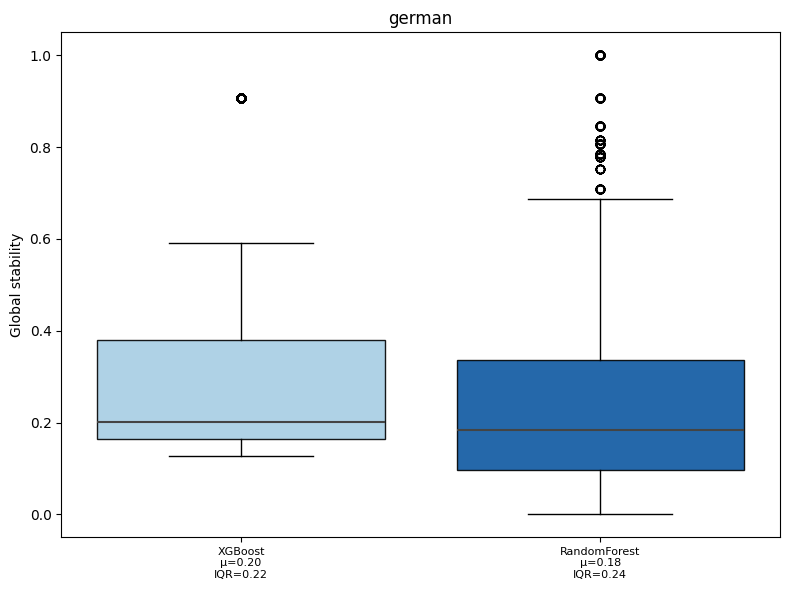

In [19]:
import matplotlib.pyplot as plt

fig, ax = plot_model_boxplot(
    df=df_all,
    dataset="german",
    imbalance=5,
    metric="rankstab_local",
    ylabel="Global stability",
    title="german"
)
plt.show()


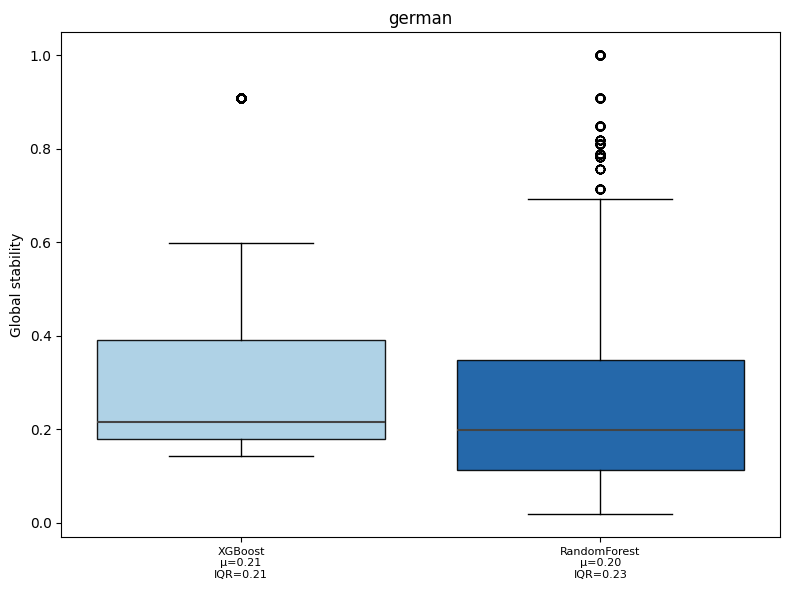

In [20]:
import matplotlib.pyplot as plt

fig, ax = plot_model_boxplot(
    df=df_all2,
    dataset="german",
    imbalance=5,
    metric="rankstab_local",
    ylabel="Global stability",
    title="german"
)
plt.show()